# Bras de drone : première pipeline aéro-structurelle (v0)

**Question posée.** Le bras d'un drone doit être **raide** (il porte la poussée du moteur) et **peu gênant pour
l'écoulement** : il est plongé dans le souffle du rotor (*downwash*), qui le pousse vers le bas et mange une
partie de la poussée. Quelle forme de **section** donne le meilleur compromis, et à quoi ressemble le bras complet ?

**Ce que fait la v0.** Une seule densité de matière $\bar\rho$ (0 = air, 1 = plastique) est optimisée par gradient.
Elle alimente deux calculs physiques réels :

* **structure** : rigidité de poutre de la section (flexion, cisaillement, torsion), calculée par éléments finis ;
* **fluide** : écoulement visqueux de Navier–Stokes autour de la section, dont on tire la **traînée**
  (la force vers le bas).

Puis on passe en **3D** : optimisation topologique du bras entier (éléments finis 3D), avec un modèle simplifié du
souffle du rotor.

**Ce que la v0 n'est pas.** Les nombres (Reynolds, matériau, charges) sont **plausibles, pas calés** : le but est
de montrer le principe avec de vrais calculs, pas de dimensionner une pièce. Les limites sont listées à la fin.

Plan : 1. modélisation · 2. la chaîne de calcul · 3. validation des briques · 4. optimisation de la section (2D)
· 5. le bras complet (3D) · 6. bilan et limites.

In [1]:
import os, sys, time, json, math, warnings
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch
from scipy.interpolate import RegularGridInterpolator

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

from aeroptimizer.arm import SectionProblem, SectionSetup, Arm3DProblem, Arm3DSetup, cell_fraction
from aeroptimizer.section import ArmLoads, BeamSection
from aeroptimizer.flow.brinkman import BrinkmanNS, brinkman_alpha, stretched_axis
from aeroptimizer.optim.loop import run
from aeroptimizer.optim.mma import MMA
from aeroptimizer.optim.continuation import Schedule
from aeroptimizer.topopt.density import simp
from aeroptimizer.topopt.overhang import OverhangParams
from aeroptimizer.io.mesh import marching_tetrahedra, write_stl, extrude, mesh_report

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

RAPIDE = os.environ.get("V0_RAPIDE") == "1"  # passage de contrôle : 6 itérations par optimisation
CACHE = RACINE / "research" / ("results_rapide" if RAPIDE else "results")
CACHE.mkdir(exist_ok=True)
RECALCULER = False  # True : relance toutes les optimisations (environ 25 min sur un portable)


def optimise(nom, pb, its=120, beta=(1.0, 16.0), beta_s=(1.0, 1.0)):
    # MMA + continuation sur la netteté de projection beta (et beta_s du surplomb). Résultat mis en cache.
    fx, fh = CACHE / f"{nom}_x.npy", CACHE / f"{nom}_hist.json"
    its = 6 if RAPIDE else its
    if fx.exists() and fh.exists() and not RECALCULER:
        return np.load(fx), json.loads(fh.read_text())
    sched = Schedule(p=(3.0, 3.0), beta=beta, beta_s=beta_s, every=max(its // 6, 1))
    n_g = len(pb.evaluate(torch.from_numpy(pb.initial_design())).g)
    t0 = time.perf_counter()
    r = run(pb, MMA(n_constraints=n_g, move=0.2), sched, max_iter=its, tol=1e-3)
    np.save(fx, r.x)
    fh.write_text(json.dumps(r.history))
    print(f"{nom} : {len(r.history)} itérations en {time.perf_counter() - t0:.0f} s ({r.stop_reason})")
    return r.x, r.history


def final(pb, x, beta=16.0, beta_s=80.0):
    # Évalue un design au réglage final de la continuation (sans gradient).
    pb.set_continuation({"p": 3.0, "beta": beta, "beta_s": beta_s})
    with torch.no_grad():
        return pb.evaluate(torch.from_numpy(np.asarray(x)))

## 1. Modélisation : quelle coupe du bras ?

Le bras est une poutre console d'axe $x$ : encastrée sur le châssis, chargée en bout par le moteur. Le souffle du
rotor descend selon $-z$ et **traverse** le bras perpendiculairement à son axe. Le problème aérodynamique
naturellement 2D est donc celui de la **section** du bras, dans le plan $(y, z)$ : on regarde le bras « en bout »,
comme une tranche de baguette, et l'air tombe dessus.

La même section détermine la rigidité du bras (théorie des poutres) : un seul dessin 2D porte les deux physiques.
Le bras est supposé imprimé couché, l'axe $z$ est aussi l'**axe d'impression** (FDM).

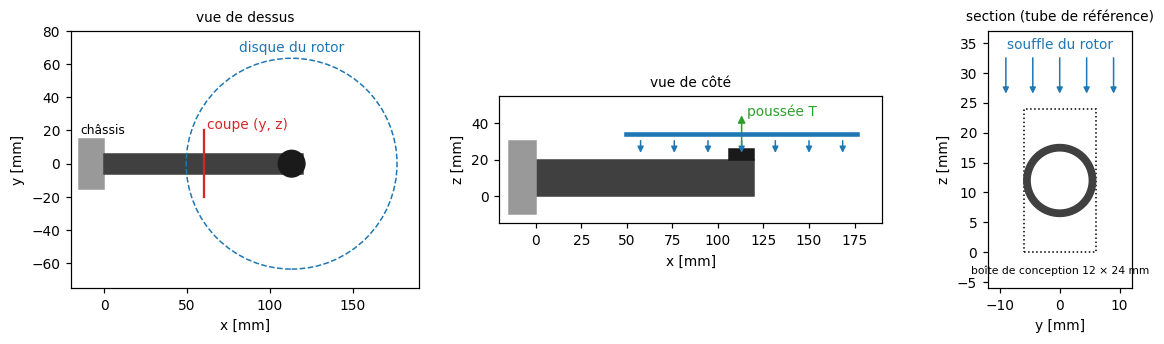

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1.5, 1.5, 0.9]})
L, R_rot = 120, 63.5
ax = axs[0]  # vue de dessus
ax.add_patch(Rectangle((-15, -15), 15, 30, color="0.6"))
ax.add_patch(Rectangle((0, -6), L, 12, color="0.25"))
ax.add_patch(Circle((L - 7, 0), R_rot, fill=False, ls="--", color="tab:blue"))
ax.add_patch(Circle((L - 7, 0), 8, color="0.1"))
ax.plot([60, 60], [-20, 20], color="tab:red", lw=1.5)
ax.text(62, 21, "coupe (y, z)", color="tab:red")
ax.text(L - 7, R_rot + 4, "disque du rotor", color="tab:blue", ha="center")
ax.text(-14, 18, "châssis", fontsize=8)
ax.set(xlim=(-20, 190), ylim=(-75, 80), aspect="equal", xlabel="x [mm]", ylabel="y [mm]", title="vue de dessus")
ax = axs[1]  # vue de côté
ax.add_patch(Rectangle((0, 0), L, 20, color="0.25"))
ax.add_patch(Rectangle((-15, -10), 15, 40, color="0.6"))
ax.add_patch(Rectangle((L - 14, 20), 14, 6, color="0.1"))
ax.plot([L - 7 - R_rot, L - 7 + R_rot], [34, 34], color="tab:blue", lw=3)
for xx in np.linspace(L - 7 - R_rot + 8, L - 7 + R_rot - 8, 7):
    ax.add_patch(FancyArrowPatch((xx, 32), (xx, 22), arrowstyle="-|>", mutation_scale=8, color="tab:blue"))
ax.add_patch(FancyArrowPatch((L - 7, 26), (L - 7, 46), arrowstyle="-|>", mutation_scale=10, color="tab:green"))
ax.text(L - 4, 44, "poussée T", color="tab:green")
ax.set(xlim=(-20, 190), ylim=(-15, 55), aspect="equal", xlabel="x [mm]", ylabel="z [mm]", title="vue de côté")
ax = axs[2]  # la section
ax.add_patch(Rectangle((-6, 0), 12, 24, fill=False, ls=":", color="k"))
th = np.linspace(0, 2 * np.pi, 100)
ax.fill(6 * np.cos(th), 12 + 6 * np.sin(th), color="0.25")
ax.fill(4.7 * np.cos(th), 12 + 4.7 * np.sin(th), color="w")
for yy in np.linspace(-9, 9, 5):
    ax.add_patch(FancyArrowPatch((yy, 33), (yy, 26), arrowstyle="-|>", mutation_scale=8, color="tab:blue"))
ax.text(0, 34, "souffle du rotor", ha="center", color="tab:blue")
ax.text(0, -3.5, "boîte de conception 12 × 24 mm", ha="center", fontsize=7)
ax.set(xlim=(-12, 12), ylim=(-6, 37), aspect="equal", xlabel="y [mm]", ylabel="z [mm]", title="section (tube de référence)")
plt.tight_layout(); plt.show()

## 2. La chaîne de calcul

Une itération d'optimisation, de la variable de conception $x$ à l'objectif. Tout est écrit en PyTorch : les
gradients viennent de la différentiation automatique, **sauf** à travers les deux solveurs (élasticité de section,
Navier–Stokes), où l'on applique la **méthode adjointe** (une résolution supplémentaire avec la même matrice).

| étape | opération | module |
|---|---|---|
| 1. symétrie | $x$ décrit la moitié droite de la section ; la gauche est son miroir | `arm.SectionProblem.rho_bar` |
| 2. filtre | moyenne pondérée sur un rayon $R$ = 1 mm (taille minimale de détail ≈ 2 buses) | `topopt/density.py` |
| 3. projection | $\tanh$ de netteté $\beta$ (1 → 16 par paliers) : pousse vers 0/1 | `topopt/density.py` |
| 4. surplomb (option) | balayage couche par couche selon $z$ : toute matière doit reposer sur la couche du dessous à 45° | `topopt/overhang.py` |
| 5a. structure | SIMP $E = E_0\,\bar\rho^3$ ; rigidités de poutre $EI_y, EI_z$, cisaillement $S_y, S_z$, torsion $GJ$ (3 résolutions EF sur la section) | `section.py` |
| 5b. compliance | $C = C_T + C_L + C_t$ : énergie des 3 cas de charge du bras console (Timoshenko) | `section.ArmLoads` |
| 6a. fluide | $\alpha(\bar\rho)$ : frottement de Brinkman (0 dans l'air, grand dans le solide) ; Navier–Stokes stationnaire, Newton | `flow/brinkman.py` |
| 6b. traînée | $D = -\int \alpha\, u_z\, d\Omega$ : force du fluide sur la matière, vers le bas | `BrinkmanNS.force` |
| 7. objectif | ε-contrainte : $\min D/D_{\rm ref}$ s.c. aire $\le f_V$, $C/C_{\rm ref} \le c_{\max}$ | `arm.SectionProblem.evaluate` |
| 8. mise à jour | MMA (méthode des asymptotes mobiles, Svanberg 1987) | `optim/mma.py` |

Les références $C_{\rm ref}, D_{\rm ref}$ sont celles d'un **tube rond de même aire** (le bras classique en tube de
carbone) : « $C/C_{\rm ref} = 1$ » se lit « aussi raide que le tube ».

**Pourquoi Navier–Stokes et pas l'écoulement potentiel ?** Un écoulement potentiel ne produit **aucune** traînée
(paradoxe de d'Alembert). La littérature d'optimisation topologique fluide résout un écoulement **visqueux** sur toute
la boîte, la matière étant un milieu poreux quasi imperméable (pénalisation de Brinkman, Borrvall & Petersson 2003) ;
la traînée est alors l'intégrale du frottement de Brinkman (Kondoh et al. 2012). On fait exactement cela.

**Pourquoi le cisaillement ?** On le verra en 4.2 : sans lui, l'optimiseur découpe la section en morceaux disjoints,
ce que la flexion seule ne sait pas voir.

### 2.1 Les équations, en bref

**Structure (section de poutre).** Pour une section de module $E(\bar\rho)$ par cellule :
$EI_y = \sum_e E_e\,[(z_e - z_c)^2 + h^2/12]\,A_e$ (idem $EI_z$ avec $y$). Trois problèmes de gauchissement partagent
le même opérateur $\mathbf K(G) = \sum_e G_e \mathbf K^0_e$ (Laplacien pondéré, une inconnue par nœud) :

* torsion de Saint-Venant : $\mathbf K\boldsymbol\omega = \mathbf b_t$, $\;GJ = \int G\,(y^2+z^2) - \mathbf b_t^\top\boldsymbol\omega$ ;
* cisaillement sous effort tranchant unitaire : $\mathbf K\boldsymbol\psi_z = \mathbf f_z$, $\mathbf f_z = \int E\,(z - z_c)/EI_y\; N$, $\;S_z = 1/(\kappa G A) = \mathbf f_z^\top\boldsymbol\psi_z$.

Console de longueur $L$ chargée en bout : $C_T = T^2\,(L^3/3EI_y + L\,S_z)$, $C_L = F^2\,(L^3/3EI_z + L\,S_y)$,
$C_t = M^2 L / GJ$. Chiffres : $L$ = 120 mm, $T$ = 8 N (poussée), $F$ = 3 N (effort latéral), $M$ = 40 N·mm
(torsion), PLA $E_0$ = 3 GPa, $\nu$ = 0,35.

**Fluide.** Sans dimension (hauteur de boîte $H$, vitesse du souffle $U$, $Re = UH/\nu$ = 100) :

$$(\mathbf u\cdot\nabla)\mathbf u = -\nabla p + \tfrac1{Re}\Delta\mathbf u - \alpha(\bar\rho)\,\mathbf u,\qquad \nabla\cdot\mathbf u = 0,
\qquad \alpha(\bar\rho) = \alpha_{\max}\frac{q\,\bar\rho}{q + 1 - \bar\rho}.$$

Éléments Q1/Q1 stabilisés (SUPG/PSPG), maillage rectiligne raffiné autour de la boîte, demi-domaine (symétrie),
entrée $\mathbf u = (0,-1)$ en haut, sortie libre en bas. La jacobienne de Newton est exacte (dérivation automatique
élément par élément), et sert aussi à l'adjoint.

$Re$ = 100 est **bien plus bas** que la réalité (≈ 10⁴ pour 10 m/s et 20 mm) : au-delà de quelques centaines,
l'écoulement réel est instationnaire et turbulent, hors de portée d'une v0. On garde l'ingrédient essentiel (une vraie
traînée de pression et de frottement, sensible au profilage) ; les valeurs de $C_D$ ne sont pas transposables.

## 3. Validation des briques

Chaque brique est confrontée à une solution connue avant d'être utilisée.

### 3.1 Rigidités de section

In [3]:
def proprietes(n, Wy, Hz, inside):
    sec = BeamSection((n, round(n * Hz / Wy)), (Wy / n, Wy / n))
    rho = cell_fraction(inside, sec.y.numpy(), sec.z.numpy() - Hz / 2, Wy / n, Wy / n)
    E = simp(rho, 1.0, 1e-9)
    return sec.stiffness(E, E)  # G = E : on compare à des formules « G = 1 »

a, b, R, t = 0.45, 0.25, 0.4, 0.05
cas = [
    ("rectangle 1×2 : EI_y = 2/3", proprietes(40, 1, 2, lambda Y, Z: np.ones_like(Y, bool)).EI_y, 2 / 3),
    ("rectangle 1×2 : κ = 5/6 → S_z = 0,6", proprietes(40, 1, 2, lambda Y, Z: np.ones_like(Y, bool)).S_z, 0.6),
    ("rectangle 1×2 : GJ = 0,2287·b³h", proprietes(40, 1, 2, lambda Y, Z: np.ones_like(Y, bool)).GJ, 0.2287 * 2),
    ("ellipse : GJ = πa³b³/(a²+b²)", proprietes(80, 1, 1, lambda Y, Z: (Y / b) ** 2 + (Z / a) ** 2 <= 1).GJ,
     math.pi * a**3 * b**3 / (a**2 + b**2)),
    ("tube : GJ = π(R⁴ − r⁴)/2", proprietes(80, 1, 1, lambda Y, Z: (Y**2 + Z**2 <= R**2) & (Y**2 + Z**2 >= (R - t) ** 2)).GJ,
     math.pi / 2 * (R**4 - (R - t) ** 4)),
    ("tube fendu : GJ ≈ 2πr t³/3", proprietes(80, 1, 1, lambda Y, Z: (Y**2 + Z**2 <= R**2) & (Y**2 + Z**2 >= (R - t) ** 2)
                                                   & ~((abs(Y) < 0.02) & (Z < 0))).GJ, 2 * math.pi * (R - t / 2) * t**3 / 3),
]
print(f"{'cas':42s} {'calcul':>11s} {'théorie':>11s} {'écart':>8s}")
for nom, v, ref in cas:
    print(f"{nom:42s} {float(v):11.5f} {ref:11.5f} {100 * (float(v) / ref - 1):+7.2f} %")

cas                                             calcul     théorie    écart
rectangle 1×2 : EI_y = 2/3                     0.66667     0.66667   +0.00 %
rectangle 1×2 : κ = 5/6 → S_z = 0,6            0.59992     0.60000   -0.01 %
rectangle 1×2 : GJ = 0,2287·b³h                0.45747     0.45740   +0.02 %
ellipse : GJ = πa³b³/(a²+b²)                   0.01688     0.01688   +0.02 %
tube : GJ = π(R⁴ − r⁴)/2                       0.01658     0.01664   -0.38 %
tube fendu : GJ ≈ 2πr t³/3                     0.00010     0.00010   +5.41 %


Le tube fendu est **160 fois** moins raide en torsion que le tube fermé : c'est ce terme qui fera préférer des
sections fermées. Et voici le test qui justifie le cisaillement : deux semelles sans âme ont presque la même
flexion qu'un profilé en I, mais l'effort tranchant ne peut pas passer de l'une à l'autre.

In [4]:
n = 30
sec = BeamSection((n, 2 * n), (1 / n, 1 / n))
y, z = sec.y.numpy(), sec.z.numpy()
semelles = (z < 0.6) | (z > 1.4)
for nom, m in (("deux semelles disjointes", semelles), ("profilé en I (âme de 0,1)", semelles | (abs(y) < 0.05))):
    E = simp(torch.from_numpy(m.astype(float)), 1.0, 1e-6)
    s = sec.stiffness(E, E)
    print(f"{nom:28s} EI_y = {float(s.EI_y):.3f}   S_z = 1/(κGA) = {float(s.S_z):10.1f}   GJ = {float(s.GJ):.4f}")

deux semelles disjointes     EI_y = 0.624   S_z = 1/(κGA) =   362426.3   GJ = 0.0903
profilé en I (âme de 0,1)    EI_y = 0.628   S_z = 1/(κGA) =        4.4   GJ = 0.0918


### 3.2 Navier–Stokes–Brinkman : le cylindre de Schäfer & Turek

Banc d'essai classique (Schäfer & Turek 1996, cas 2D-1) : cylindre de diamètre 0,1 dans un canal de 0,41,
profil d'entrée parabolique, $Re$ = 20. Référence : $C_D$ = 5,5795. Ici le cylindre n'est **pas** maillé : il est
« peint » dans la grille par la densité, exactement comme le seront les designs.

In [5]:
def cylindre(n_D, alpha_max=1e5):
    h = 0.1 / n_D
    a0 = np.linspace(0, 0.41, round(0.41 / h) + 1)
    a1 = stretched_axis((2.2 - round(0.4 / h) * h, 2.2), h, 0.0, 2.2, 1.06)
    nodes = np.stack(np.meshgrid(a0, a1, indexing="ij"), -1).reshape(-1, 2)
    fixed, vals = torch.zeros(len(nodes), 3, dtype=torch.bool), torch.zeros(len(nodes), 3)
    paroi = torch.from_numpy(np.isclose(nodes[:, 0], 0) | np.isclose(nodes[:, 0], 0.41))
    entree = torch.from_numpy(np.isclose(nodes[:, 1], 2.2))
    for m in (paroi, entree):
        fixed[m, 0] = fixed[m, 1] = True
    yy = torch.from_numpy(nodes[:, 0])
    vals[entree & ~paroi, 1] = -(4 * 0.3 * yy * (0.41 - yy) / 0.41**2)[entree & ~paroi]
    ns = BrinkmanNS((a0, a1), 1000.0, fixed.reshape(-1), vals.reshape(-1))  # mu = 1e-3
    c = ns.centres.numpy()
    rho = cell_fraction(lambda Y, Z: (Y - 0.2) ** 2 + (Z - 2.0) ** 2 <= 0.05**2, c[:, 0], c[:, 1], h, h)
    alpha = brinkman_alpha(rho, alpha_max, q=1.0)
    t0 = time.perf_counter()
    sol = ns.newton(alpha)
    F = ns.force(sol.U, alpha)
    return ns, sol, -float(F[1]) / (0.5 * 0.2**2 * 0.1), time.perf_counter() - t0

print(f"{'D/h':>4s} {'éléments':>9s} {'C_D':>7s} {'écart':>8s} {'Newton':>7s} {'temps':>6s}")
for n_D in (10, 20, 30):
    ns_cyl, sol_cyl, CD, dt = cylindre(n_D)
    print(f"{n_D:4d} {ns_cyl.grid.n_elems:9d} {CD:7.3f} {100 * (CD / 5.5795 - 1):+7.1f} % {sol_cyl.newton_its:7d} {dt:5.1f} s")

 D/h  éléments     C_D    écart  Newton  temps


  10      3362   6.178   +10.7 %       5   1.6 s


  20     10906   5.918    +6.1 %       4   3.4 s


  30     22017   5.796    +3.9 %       4   8.7 s


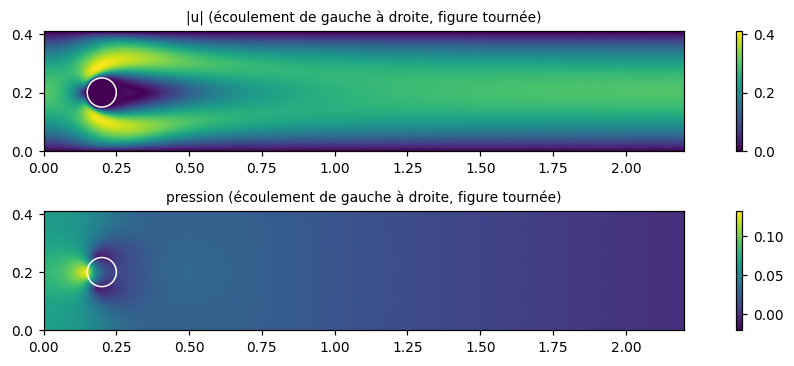

In [6]:
u0, u1, p = sol_cyl.fields(ns_cyl.shape)
a0, a1 = ns_cyl.axes
fig, axs = plt.subplots(2, 1, figsize=(10, 3.4))
for ax, champ, titre in ((axs[0], np.hypot(u0, u1), "|u|"), (axs[1], p, "pression")):
    m = ax.pcolormesh(2.2 - a1[::-1], a0, champ[:, ::-1], shading="gouraud", cmap="viridis")
    ax.add_patch(Circle((0.2, 0.2), 0.05, fill=False, color="w"))
    ax.set(aspect="equal", xlim=(0, 2.2), title=titre + " (écoulement de gauche à droite, figure tournée)")
    plt.colorbar(m, ax=ax, fraction=0.02)
plt.tight_layout(); plt.show()

La traînée converge **par excès** vers la référence (+11 %, +6 %, +4 % quand la maille est divisée par 3) :
l'interface diffuse rend le cylindre légèrement « plus gros » qu'en réalité, et un peu d'air filtre à travers le
solide poreux. C'est le comportement connu de la méthode de Brinkman. Les sections du § 4 sont calculées avec
24 mailles sur la largeur de la boîte (niveau du milieu, ≈ +6 %) : pour **comparer des formes** entre elles sur la même grille, ce biais
commun est sans conséquence.

### 3.3 Les gradients

L'optimiseur n'a besoin que de deux choses justes : les valeurs et leurs dérivées. On compare le gradient adjoint
de toute la chaîne (filtre → projection → section EF → Navier–Stokes) à des différences finies, dans une direction
aléatoire.

In [7]:
pb_test = SectionProblem(SectionSetup(W=8.0, H=12.0, h=1.0, R=1.5, flow_box=(2.0, 1.5, 2.5, 0.25), stretch=1.3), mode="eps")
pb_test.set_continuation({"p": 3.0, "beta": 2.0, "beta_s": 1.0})
x0 = torch.from_numpy(pb_test.initial_design()) + 0.1 * torch.rand(pb_test.n_design)
d, e = torch.randn_like(x0), 1e-5
for cle in ("C", "D"):
    x = x0.clone().requires_grad_()
    (g,) = torch.autograd.grad(pb_test.evaluate(x).terms[cle], x)
    with torch.no_grad():
        fd = (pb_test.evaluate(x0 + e * d).terms[cle] - pb_test.evaluate(x0 - e * d).terms[cle]) / (2 * e)
    print(f"d{cle}/dx · d : adjoint = {float(g @ d):+.10e}   différences finies = {float(fd):+.10e}")

dC/dx · d : adjoint = -3.2307499181e+01   différences finies = -3.2307498068e+01
dD/dx · d : adjoint = +7.1754824741e-02   différences finies = +7.1754683761e-02


## 4. Optimisation de la section (2D)

Boîte de conception 12 × 24 mm (mailles de 0,5 mm : 24 × 48 cellules, 576 variables grâce à la symétrie), 30 %
de matière, soit l'aire du tube de référence (Ø 12 mm, paroi 1,7 mm).

### 4.0 La référence : le tube rond

tube de référence : {'C_T': 12.8627, 'C_L': 1.8088, 'C_t': 0.0897, 'C': 14.7613, 'D': 0.4001, 'C_D': 1.6003, 'area': 0.3003}
C_D (sur la largeur de boîte) = 1.600 ; part de la torsion dans C : 0.6%


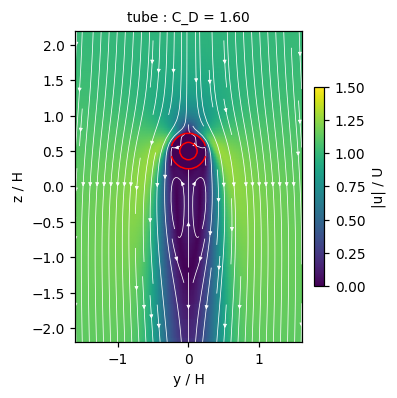

In [8]:
SETUP = SectionSetup(W=12.0, H=24.0)
pb_ref = SectionProblem(SETUP)
pb_ref.p = 1.0
with torch.no_grad():
    t_ref, st_ref, U_ref, _ = pb_ref.physics(pb_ref.tube())
print("tube de référence :", {k: round(float(v), 4) for k, v in t_ref.items()})
print(f"C_D (sur la largeur de boîte) = {float(t_ref['C_D']):.3f} ; part de la torsion dans C : {float(t_ref['C_t'] / t_ref['C']):.1%}")


def ecoulement(ax, pb, U, rho, titre, zoom=(1.6, -2.2, 2.2)):
    # |u| et lignes de courant autour de la section (demi-domaine calculé, miroir pour l'affichage).
    V = U.detach().numpy().reshape(*(n + 1 for n in pb.flow.shape), 3)
    u0, u1 = V[..., 0], V[..., 1]
    ay, az = pb.flow.axes
    H = pb.setup.H
    Y = np.concatenate([-ay[::-1], ay[1:]]); U0 = np.concatenate([-u0[::-1], u0[1:]]); U1 = np.concatenate([u1[::-1], u1[1:]])
    m = ax.pcolormesh(Y, az, np.hypot(U0, U1).T, shading="gouraud", cmap="viridis", vmin=0, vmax=1.5)
    yr, zr = np.linspace(-zoom[0], zoom[0], 120), np.linspace(zoom[1], zoom[2], 200)
    gy, gz = np.meshgrid(yr, zr, indexing="ij")
    iu = RegularGridInterpolator((Y, az), U0)(np.stack([gy, gz], -1)); iv = RegularGridInterpolator((Y, az), U1)(np.stack([gy, gz], -1))
    ax.streamplot(yr, zr, iu.T, iv.T, color="w", linewidth=0.5, density=1.1, arrowsize=0.5)
    W, h = pb.setup.W, pb.setup.h
    yc, zc = ((np.arange(rho.shape[0]) + 0.5) * h - W / 2) / H, (np.arange(rho.shape[1]) + 0.5) * h / H
    ax.contour(yc, zc, np.asarray(rho).T, [0.5], colors="r", linewidths=1)
    ax.set(xlim=(-zoom[0], zoom[0]), ylim=(zoom[1], zoom[2]), aspect="equal", title=titre, xlabel="y / H", ylabel="z / H")
    return m


fig, ax = plt.subplots(figsize=(3.6, 4.6))
m = ecoulement(ax, pb_ref, U_ref, pb_ref.tube(), f"tube : C_D = {float(t_ref['C_D']):.2f}")
plt.colorbar(m, ax=ax, fraction=0.04, label="|u| / U"); plt.tight_layout(); plt.show()

Le sillage derrière le tube est une longue zone d'eau morte (bulle de recirculation) : c'est la traînée de pression
d'un corps non profilé. Le souffle du rotor vient d'en haut ; la boîte de conception est le rectangle
$[-0{,}25 ; 0{,}25]\times[0 ; 1]$ en unités de $H$.

### 4.1 Rigidité seule

D'abord une optimisation classique : minimiser la compliance $C$ à 30 % de matière, sans se soucier de l'air.

In [9]:
def montre(ax, pb, rho, titre):
    W, H = pb.setup.W, pb.setup.H
    ax.imshow(np.asarray(rho).T, origin="lower", extent=(-W / 2, W / 2, 0, H), cmap="gray_r", vmin=0, vmax=1)
    ax.set(title=titre, xticks=[-W / 2, 0, W / 2], yticks=[0, H / 2, H])


def resume(nom, res):
    t = res.terms
    print(f"{nom:28s} C/C_tube = {float(t['C_hat']):5.2f}   D/D_tube = {float(t['D_hat']):5.2f}   "
          f"C_D = {float(t['C_D']):5.2f}   aire = {float(t['area']):.3f}   "
          f"[C_T {float(t['C_T']):.2f}, C_L {float(t['C_L']):.2f}, C_t {float(t['C_t']):.2f}]")


pb_C = SectionProblem(SETUP, mode="weighted", weights={"C": 1.0, "D": 0.0})
x_C, h_C = optimise("s2d_rigidite", pb_C)
res_C = final(pb_C, x_C)
resume("rigidité seule", res_C)

rigidité seule               C/C_tube =  0.20   D/D_tube =  1.14   C_D =  1.83   aire = 0.300   [C_T 1.96, C_L 0.95, C_t 0.04]


### 4.2 Ce que l'optimiseur exploite si on oublie le cisaillement

Même problème couplé que plus bas (traînée minimale à rigidité au moins égale au tube), mais avec la flexion
d'Euler–Bernoulli seule, sans le terme de cisaillement.

In [10]:
from dataclasses import replace
pb_nos = SectionProblem(replace(SETUP, loads=ArmLoads(shear=False)), mode="eps", c_max=1.0)
x_nos, _ = optimise("s2d_sans_cisaillement", pb_nos)
res_nos = final(pb_nos, x_nos)
resume("sans cisaillement", res_nos)
pb_chk = SectionProblem(SETUP, mode="eps", c_max=1.0)  # le même design, évalué AVEC cisaillement
res_chk = final(pb_chk, x_nos)
resume("  ... réévalué avec", res_chk)

sans cisaillement            C/C_tube =  1.00   D/D_tube =  0.66   C_D =  1.06   aire = 0.300   [C_T 3.50, C_L 10.74, C_t 0.38]


  ... réévalué avec          C/C_tube = 523.45   D/D_tube =  0.66   C_D =  1.06   aire = 0.300   [C_T 7715.71, C_L 10.76, C_t 0.38]


L'optimiseur coupe la section en **deux corps en tandem**. Pour la flexion d'Euler–Bernoulli, la matière proche de
l'axe neutre ne sert presque à rien, et deux morceaux séparés comptent comme une seule poutre (théorème de Huygens) :
la coupure est **gratuite** dans ce modèle, l'optimiseur s'en sert pour placer la matière où elle sert l'aérodynamique.
Mais rien ne relie les deux morceaux : réévalué avec le cisaillement, ce design est **plus de 500 fois** trop souple.
C'est la leçon habituelle de l'optimisation topologique : **l'optimiseur trouve toutes les failles du modèle**. Le
terme de cisaillement les referme (§ 3.1).

### 4.3 Traînée minimale à rigidité égale au tube

ε-contrainte, C ≤ C_tube     C/C_tube =  1.00   D/D_tube =  0.65   C_D =  1.04   aire = 0.300   [C_T 4.43, C_L 10.06, C_t 0.29]


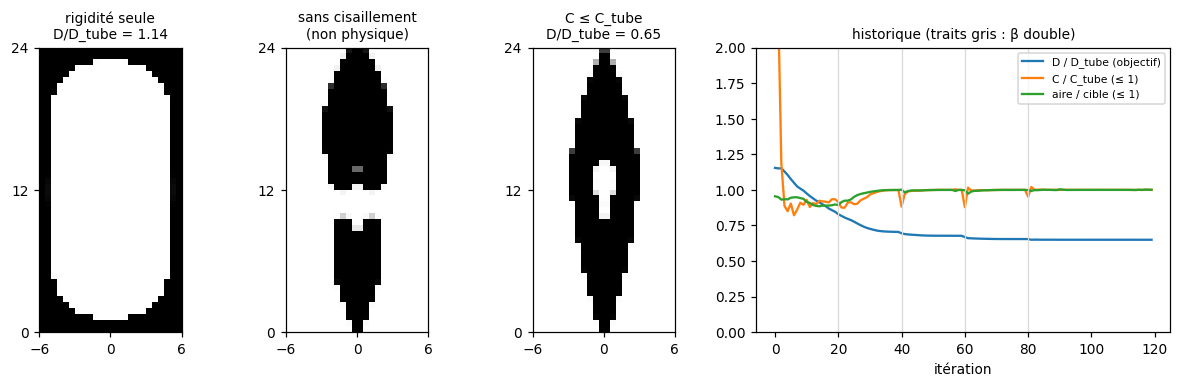

In [11]:
pb_eps = SectionProblem(SETUP, mode="eps", c_max=1.0)
x_eps, h_eps = optimise("s2d_eps1", pb_eps)
res_eps = final(pb_eps, x_eps)
resume("ε-contrainte, C ≤ C_tube", res_eps)

fig, axs = plt.subplots(1, 4, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 2.2]})
montre(axs[0], pb_C, res_C.state[0], f"rigidité seule\nD/D_tube = {float(res_C.terms['D_hat']):.2f}")
montre(axs[1], pb_nos, res_nos.state[0], "sans cisaillement\n(non physique)")
montre(axs[2], pb_eps, res_eps.state[0], f"C ≤ C_tube\nD/D_tube = {float(res_eps.terms['D_hat']):.2f}")
ax = axs[3]
it = [r["it"] for r in h_eps]
ax.plot(it, [r["D_hat"] for r in h_eps], label="D / D_tube (objectif)")
ax.plot(it, [r["C_hat"] for r in h_eps], label="C / C_tube (≤ 1)")
ax.plot(it, [r["area"] / SETUP.volfrac for r in h_eps], label="aire / cible (≤ 1)")
for k, r in enumerate(h_eps[1:], 1):
    if r["beta"] != h_eps[k - 1]["beta"]:
        ax.axvline(k, color="0.85", lw=0.8)
ax.set(xlabel="itération", ylim=(0, 2), title="historique (traits gris : β double)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

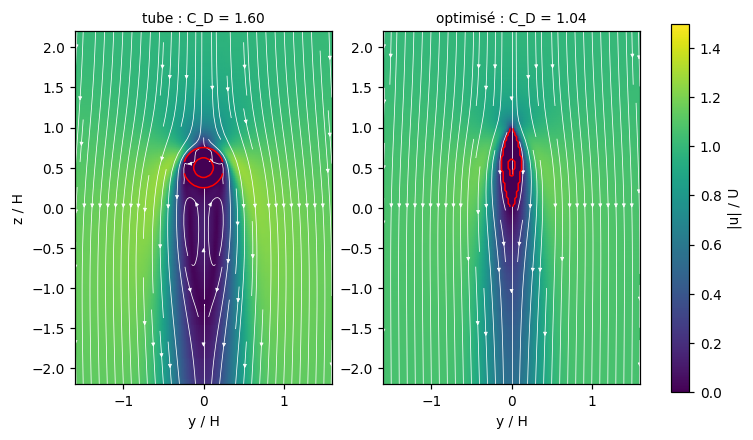

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(7.2, 4.6))
ecoulement(axs[0], pb_ref, U_ref, pb_ref.tube(), f"tube : C_D = {float(t_ref['C_D']):.2f}")
m = ecoulement(axs[1], pb_eps, res_eps.state[2], res_eps.state[0], f"optimisé : C_D = {float(res_eps.terms['C_D']):.2f}")
axs[1].set_ylabel("")
plt.colorbar(m, ax=axs, fraction=0.03, label="|u| / U"); plt.show()

À rigidité égale, la section optimisée est un **fuseau creux**, pointu en amont et en aval, environ 3,5 fois plus
haut que large : sa traînée est 35 % plus faible que celle du tube. Le sillage mort du tube disparaît presque. Le fuseau à deux pointes est la forme connue du corps de traînée
minimale à bas Reynolds (Pironneau 1973), retrouvée ici sans qu'on la lui ait dictée. L'intérieur creux (cellule
fermée) vient de la torsion et de la flexion latérale. À Reynolds réaliste, on attend plutôt un nez arrondi et une
queue effilée (profil NACA).

### 4.4 Le compromis : front de Pareto

On balaie la rigidité exigée $c_{\max}$ : plus on accepte de souplesse, plus la section peut s'affiner.

In [13]:
C_MAX = (0.6, 0.8, 1.0, 1.5, 2.5)
pareto = {}
for c in C_MAX:
    pb_c = SectionProblem(SETUP, mode="eps", c_max=c)
    x_c, _ = optimise("s2d_eps1" if c == 1.0 else f"s2d_eps{c:g}", pb_c)
    pareto[c] = (pb_c, final(pb_c, x_c))
    resume(f"c_max = {c:g}", pareto[c][1])

c_max = 0.6                  C/C_tube =  0.60   D/D_tube =  0.71   C_D =  1.14   aire = 0.300   [C_T 3.17, C_L 5.53, C_t 0.16]


c_max = 0.8                  C/C_tube =  0.80   D/D_tube =  0.67   C_D =  1.07   aire = 0.300   [C_T 3.72, C_L 7.87, C_t 0.22]


c_max = 1                    C/C_tube =  1.00   D/D_tube =  0.65   C_D =  1.04   aire = 0.300   [C_T 4.43, C_L 10.06, C_t 0.29]


c_max = 1.5                  C/C_tube =  1.50   D/D_tube =  0.61   C_D =  0.98   aire = 0.266   [C_T 6.41, C_L 15.35, C_t 0.43]


c_max = 2.5                  C/C_tube =  2.50   D/D_tube =  0.58   C_D =  0.93   aire = 0.201   [C_T 11.82, C_L 24.37, C_t 0.72]


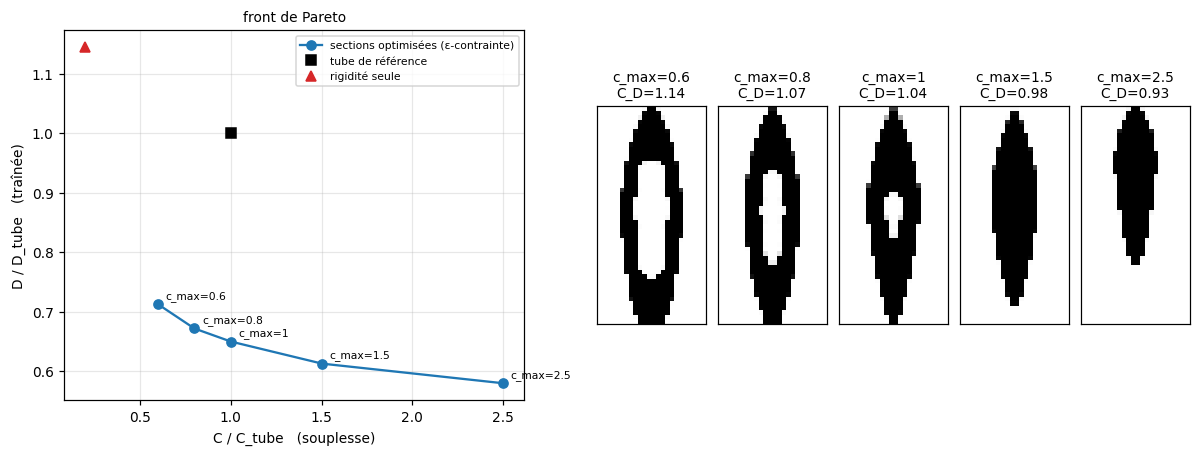

In [14]:
fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_axes([0.06, 0.12, 0.38, 0.8])
pts = [(float(r.terms["C_hat"]), float(r.terms["D_hat"])) for _, r in pareto.values()]
ax.plot(*zip(*pts), "o-", label="sections optimisées (ε-contrainte)")
ax.plot(1, 1, "s", color="k", label="tube de référence")
ax.plot(float(res_C.terms["C_hat"]), float(res_C.terms["D_hat"]), "^", color="tab:red", label="rigidité seule")
for c, (cx, dy) in zip(C_MAX, pts):
    ax.annotate(f"c_max={c:g}", (cx, dy), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax.set(xlabel="C / C_tube   (souplesse)", ylabel="D / D_tube   (traînée)", title="front de Pareto")
ax.grid(alpha=0.3); ax.legend(fontsize=7)
for k, (c, (pb_c, r)) in enumerate(pareto.items()):
    a = fig.add_axes([0.5 + k * 0.1, 0.12, 0.09, 0.8])
    montre(a, pb_c, r.state[0], f"c_max={c:g}\nC_D={float(r.terms['C_D']):.2f}")
    a.set(xticks=[], yticks=[])
plt.show()

Lecture : le tube (carré noir) est **dominé**. À traînée égale on peut être beaucoup plus raide, et à rigidité égale
beaucoup moins traînant. Le long du front, la section passe d'un profil épais et creux (rigide) à une lame fine
(faible traînée), et la compliance latérale $C_L$ grimpe à mesure que la largeur fond.

### 4.5 Imprimabilité : pas de surplomb au-delà de 45°

Imprimée couchée, la section est construite couche par couche selon $z$ : toute matière doit reposer sur la couche
du dessous, avec une pente d'au plus 45° (règle d'une cellule ; un pont de 2 cellules, 1 mm, reste admis). On ajoute
le filtre de surplomb (Langelaar 2017) dans la chaîne, à l'étape 4.

C ≤ C_tube + surplomb        C/C_tube =  1.00   D/D_tube =  0.66   C_D =  1.05   aire = 0.300   [C_T 4.69, C_L 9.79, C_t 0.28]


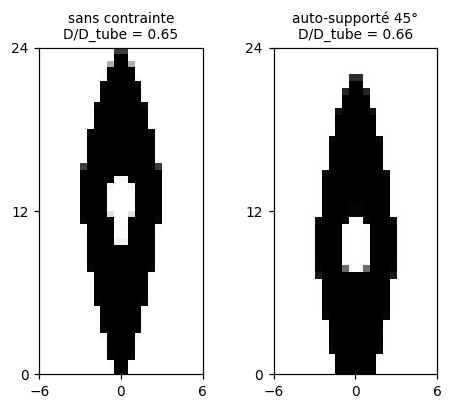

In [15]:
pb_ovh = SectionProblem(replace(SETUP, overhang=OverhangParams(beta_s=10.0)), mode="eps", c_max=1.0)
x_ovh, _ = optimise("s2d_eps1_surplomb", pb_ovh, beta_s=(10.0, 80.0))
res_ovh = final(pb_ovh, x_ovh)
resume("C ≤ C_tube + surplomb", res_ovh)
fig, axs = plt.subplots(1, 2, figsize=(4.4, 3.8))
montre(axs[0], pb_eps, res_eps.state[0], f"sans contrainte\nD/D_tube = {float(res_eps.terms['D_hat']):.2f}")
montre(axs[1], pb_ovh, res_ovh.state[0], f"auto-supporté 45°\nD/D_tube = {float(res_ovh.terms['D_hat']):.2f}")
plt.tight_layout(); plt.show()

## 5. Le bras complet (3D)

La section dit **quelle forme** donner au profil. Reste à savoir **où mettre la matière le long du bras** : faut-il
la même section partout ? On passe en éléments finis 3D (hexaèdres Q1, l'opérateur sans matrice du projet).

* boîte 120 × 24 × 20 mm, mailles de 2 mm (60 × 12 × 10 = 7 200 éléments, 26 000 inconnues), 15 % de matière ;
* encastrement à la racine ($x$ = 0), support moteur plein de 14 mm en bout ;
* les **trois mêmes cas de charge** (poussée, effort latéral, couple de torsion), résolus avec **une seule**
  factorisation (trois seconds membres) ;
* aérodynamique : on ne peut pas résoudre Navier–Stokes en 3D dans une v0. On utilise la **théorie des tranches**
  (Hoerner) : chaque colonne verticale $(x, y)$ du bras située sous le disque du rotor reçoit le souffle et subit
  $q\,C_D$ fois sa largeur occupée. L'occupation d'une colonne, « y a-t-il de la matière quelque part sur la
  verticale ? », s'écrit de façon dérivable $1 - \prod_z (1 - \bar\rho)$. Ce modèle ignore le profilage (c'est le
  rôle de l'étude 2D) et ne voit que la **surface projetée sous le rotor**.

### 5.1 Le modèle de poutre 2D est-il fidèle à la 3D ?

Avant d'optimiser, on vérifie le lien entre les deux échelles : la compliance 3D (éléments finis) de barres
extrudées doit correspondre à celle que prédit la section 2D par la théorie des poutres (Timoshenko, avec le support
moteur rigide en bout).

In [16]:
S3 = Arm3DSetup()
pb3 = Arm3DProblem(S3, weights={"C": 1.0, "D": 0.0})
nx, ny, nz = pb3.shape
print(f"grille {pb3.shape}, {pb3.grid.n_elems} éléments, {pb3.op.n_dofs} inconnues ; références (tube) : {pb3.refs}")


def poutre(rho_sec, h):
    # Compliances (poussée, latéral, torsion) d'une console à section constante + support rigide de longueur m.
    sec = BeamSection(rho_sec.shape, (h, h))
    E = S3.E0 * simp(rho_sec.reshape(-1), 1.0, 1e-9)
    st = sec.stiffness(E, E / (2 * (1 + S3.nu)))
    a, m = S3.L - S3.mount, S3.mount
    out = []
    for F, EI, S in ((S3.thrust, st.EI_y, st.S_z), (S3.lateral, st.EI_z, st.S_y)):
        M = F * m / 2
        w = F * a**3 / (3 * EI) + M * a**2 / (2 * EI) + F * a * S
        th = F * a**2 / (2 * EI) + M * a / EI
        out.append(float(F * (w + th * m / 2)))
    return out + [float(S3.torque**2 * a / st.GJ)]


r_in = math.sqrt(100 - S3.volfrac * S3.W * S3.H / math.pi)
formes = {"barre pleine 24×20": lambda Y, Z: np.ones_like(Y, bool),
          "barre 12×20": lambda Y, Z: abs(Y) <= 6,
          "tube Ø20 (référence)": lambda Y, Z: (Y**2 + (Z - 10) ** 2 <= 100) & (Y**2 + (Z - 10) ** 2 >= r_in**2)}
print(f"{'':22s} {'C_T 3D':>8s} {'poutre':>8s} {'C_L 3D':>8s} {'poutre':>8s} {'C_t 3D':>8s} {'poutre':>8s}")
for nom, inside in formes.items():
    f = 8
    yf = (np.arange(ny * f) + 0.5) * S3.h / f - S3.W / 2; zf = (np.arange(nz * f) + 0.5) * S3.h / f
    Yf, Zf = np.meshgrid(yf, zf, indexing="ij")
    fin = cell_fraction(inside, Yf.reshape(-1), Zf.reshape(-1), S3.h / f, S3.h / f).reshape(ny * f, nz * f)
    yc = (np.arange(ny) + 0.5) * S3.h - S3.W / 2; zc = (np.arange(nz) + 0.5) * S3.h
    Yc, Zc = np.meshgrid(yc, zc, indexing="ij")
    gros = cell_fraction(inside, Yc.reshape(-1), Zc.reshape(-1), S3.h, S3.h).reshape(ny, nz)
    rho3 = gros[None].expand(nx, ny, nz).clone(); rho3[pb3.masks.solid] = 1.0
    pb3.p = 1.0
    with torch.no_grad():
        t3, _ = pb3.physics(rho3)
    b = poutre(fin, S3.h / f)
    print(f"{nom:22s} " + " ".join(f"{float(t3[k]):8.3f} {v:8.3f}" for k, v in zip(("C_T", "C_L", "C_t"), b)))

grille (60, 12, 10), 7200 éléments, 26169 inconnues ; références (tube) : {'C': 3.858454072858432, 'D': 967.3287873421796}
                         C_T 3D   poutre   C_L 3D   poutre   C_t 3D   poutre


barre pleine 24×20        0.639    0.656    0.066    0.065    0.005    0.005


barre 12×20               1.287    1.313    0.499    0.505    0.021    0.021


tube Ø20 (référence)      3.348    3.387    0.485    0.476    0.026    0.024


Accord à 1–3 % sur les trois cas de charge, y compris la torsion : la réduction « section 2D + théorie des poutres »
utilisée en partie 4 est **cohérente** avec l'élasticité 3D complète.

### 5.2 Optimisation 3D : rigidité seule, puis rigidité + souffle du rotor

Somme pondérée $J = w_c\,C/C_{\rm tube} + w_a\,D/D_{\rm tube}$ à 15 % de matière (le tube Ø 20 mm de même masse sert
de référence). Deux calculs : $w_a = 0$ (rigidité seule) et $w_a = 0{,}3$.

In [17]:
pb3_C = Arm3DProblem(S3, weights={"C": 1.0, "D": 0.0})
x3_C, h3_C = optimise("a3d_rigidite", pb3_C, its=150, beta=(1.0, 8.0))
pb3_A = Arm3DProblem(S3, weights={"C": 0.7, "D": 0.3})
x3_A, h3_A = optimise("a3d_aero03", pb3_A, its=150, beta=(1.0, 8.0))
r3_C, r3_A = final(pb3_C, x3_C, beta=8.0), final(pb3_A, x3_A, beta=8.0)
for nom, r in (("rigidité seule", r3_C), ("rigidité + souffle (w_a = 0,3)", r3_A)):
    t = r.terms
    print(f"{nom:32s} C/C_tube = {float(t['C_hat']):.2f}   D/D_tube = {float(t['D_hat']):.2f}   volume = {float(t['vol']):.3f}   "
          f"[C_T {float(t['C_T']):.2f}, C_L {float(t['C_L']):.2f}, C_t {float(t['C_t']):.3f}]")

rigidité seule                   C/C_tube = 0.91   D/D_tube = 0.72   volume = 0.150   [C_T 2.89, C_L 0.45, C_t 0.157]
rigidité + souffle (w_a = 0,3)   C/C_tube = 0.94   D/D_tube = 0.46   volume = 0.150   [C_T 2.94, C_L 0.54, C_t 0.166]


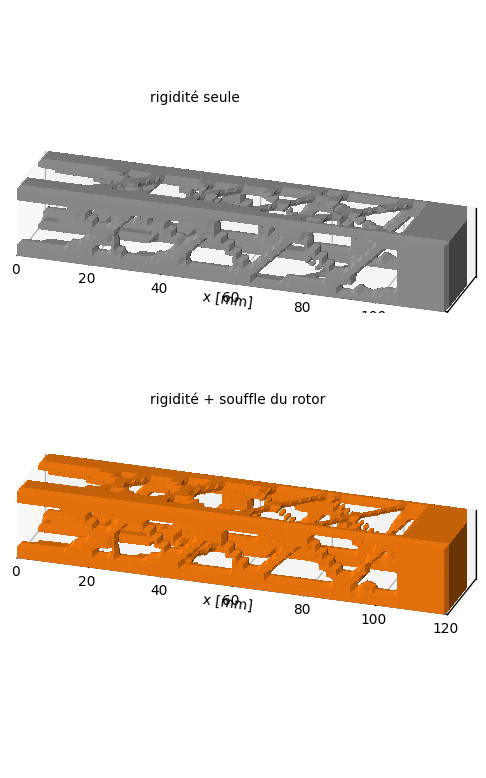

In [18]:
def rendu(ax, rho, titre, couleur="tab:orange"):
    V, F = marching_tetrahedra(np.asarray(rho), 0.5, (S3.h,) * 3)
    ax.plot_trisurf(V[:, 0], V[:, 1] - S3.W / 2, F, V[:, 2], color=couleur, linewidth=0, shade=True, antialiased=False)
    ax.set_proj_type("ortho"); ax.set_box_aspect((S3.L, S3.W, S3.H)); ax.view_init(elev=24, azim=-72)
    ax.set(xlim=(0, S3.L), ylim=(-S3.W / 2, S3.W / 2), zlim=(0, S3.H))
    ax.set_yticks([]); ax.set_zticks([]); ax.set_xlabel("x [mm]")
    ax.text2D(0.3, 0.8, titre, transform=ax.transAxes)
    return V, F


rho3_C = r3_C.state[0].numpy(); rho3_A = r3_A.state[0].numpy()
fig = plt.figure(figsize=(11, 5.5))
rendu(fig.add_axes([-0.35, 0.42, 1.7, 0.75], projection="3d"), rho3_C, "rigidité seule", "0.6")
rendu(fig.add_axes([-0.35, -0.08, 1.7, 0.75], projection="3d"), rho3_A, "rigidité + souffle du rotor")
plt.show()

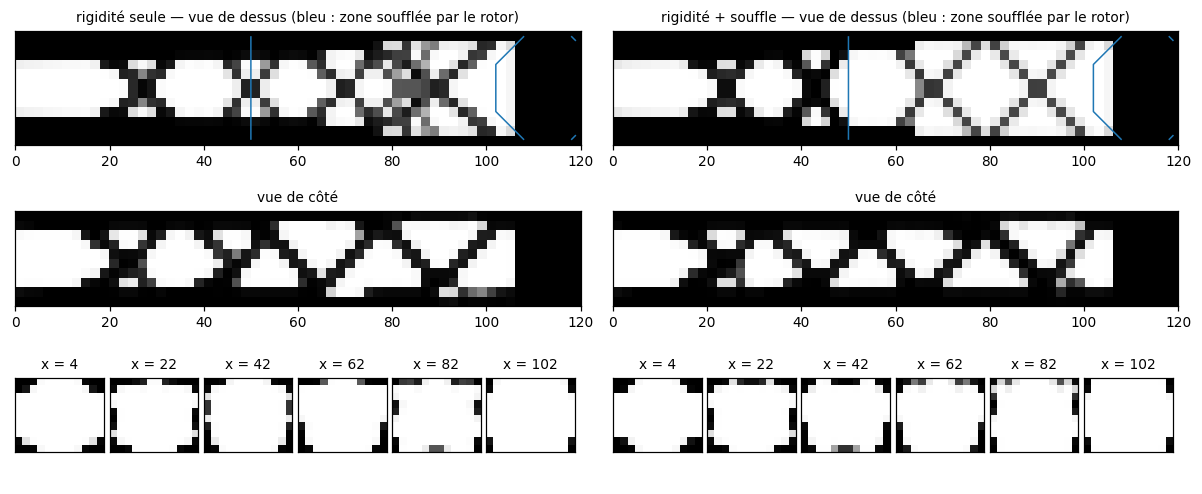

In [19]:
fig, axs = plt.subplots(3, 2, figsize=(11, 4.6), gridspec_kw={"height_ratios": [1.2, 1, 1]})
ext_top = (0, S3.L, -S3.W / 2, S3.W / 2)
for j, (rho, nom) in enumerate(((rho3_C, "rigidité seule"), (rho3_A, "rigidité + souffle"))):
    occ = 1 - np.prod(1 - rho, axis=2)
    ax = axs[0, j]
    ax.imshow(occ.T, origin="lower", extent=ext_top, cmap="gray_r", vmin=0, vmax=1, aspect="equal")
    ax.contour((np.arange(nx) + 0.5) * S3.h, (np.arange(ny) + 0.5) * S3.h - S3.W / 2, pb3.q_map.numpy().T, [0.5], colors="tab:blue", linewidths=1)
    ax.set(title=f"{nom} — vue de dessus (bleu : zone soufflée par le rotor)", yticks=[])
    axs[1, j].imshow(rho.max(axis=1).T, origin="lower", extent=(0, S3.L, 0, S3.H), cmap="gray_r", vmin=0, vmax=1)
    axs[1, j].set(title="vue de côté", yticks=[])
    for k, ix in enumerate(np.linspace(2, nx - 9, 6).astype(int)):
        a = axs[2, j].inset_axes([k / 6, 0, 1 / 6 - 0.01, 1])
        a.imshow(rho[ix].T, origin="lower", cmap="gray_r", vmin=0, vmax=1, extent=(-S3.W / 2, S3.W / 2, 0, S3.H))
        a.set(xticks=[], yticks=[], title=f"x = {ix * S3.h:.0f}", )
    axs[2, j].axis("off")
plt.tight_layout(); plt.show()

Lecture des deux bras :

* **rigidité seule** : une **poutre-caisson en treillis**. Quatre membrures longitudinales aux coins de la boîte
  (le plus loin possible des axes neutres : flexion verticale, latérale et torsion), reliées par des diagonales
  (treillis de Warren, bien visible en vue de côté) sur les quatre faces. Elle est déjà un peu plus raide que le
  tube de même masse.
* **avec le souffle** : même ossature, mais sous le rotor l'optimiseur **vide les faces haute et basse** (vue de
  dessus : la zone bleue devient presque transparente) et garde les flancs verticaux, que le souffle voit par la
  tranche. La traînée du bras chute de 0,72 à 0,46 fois celle du tube, pour 3 % de souplesse en plus seulement.
  On retrouve en 3D le message de la section : sous le souffle, la matière doit être **verticale**.

### 5.3 Pièces imprimables

Les deux sorties sont des maillages STL fermés : le bras 3D optimisé, et la section 2D auto-supportée de § 4.5
extrudée sur la longueur du bras.

bras 3D : {'n_faces': 21444, 'watertight': True, 'volume': 13259.212912542658}
section extrudée : {'n_faces': 64592, 'watertight': True, 'volume': 10376.796026613018}


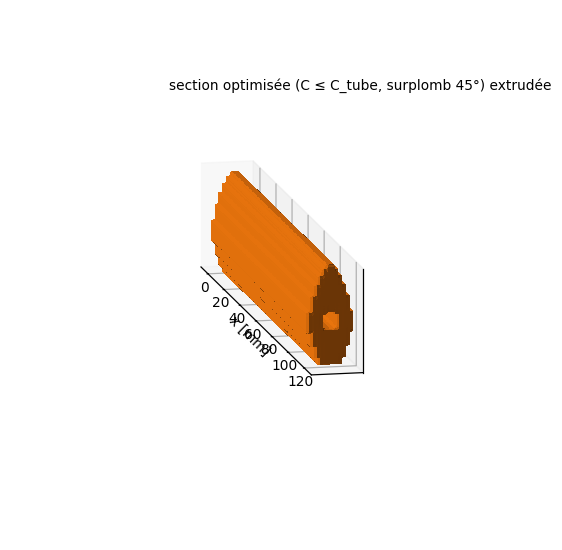

In [20]:
V, F = marching_tetrahedra(rho3_A, 0.5, (S3.h,) * 3)
write_stl(CACHE / "bras_3d_aero.stl", V, F)
print("bras 3D :", {k: v for k, v in mesh_report(V, F).items() if k in ("n_faces", "watertight", "volume")})

rho_s = res_ovh.state[0].numpy()
n_long = 60
champ = np.repeat(rho_s[None], n_long, axis=0)  # (x, y, z) : la section répétée le long du bras
h_s = SETUP.h
Vs, Fs = marching_tetrahedra(champ, 0.5, (S3.L / n_long, h_s, h_s))
write_stl(CACHE / "bras_section_extrudee.stl", Vs, Fs)
print("section extrudée :", {k: v for k, v in mesh_report(Vs, Fs).items() if k in ("n_faces", "watertight", "volume")})
fig = plt.figure(figsize=(11, 3.2))
ax = fig.add_axes([-0.35, -0.25, 1.7, 1.5], projection="3d")
ax.plot_trisurf(Vs[:, 0], Vs[:, 1] - SETUP.W / 2, Fs, Vs[:, 2], color="tab:orange", linewidth=0, antialiased=False)
ax.set_proj_type("ortho"); ax.set_box_aspect((S3.L, SETUP.W, SETUP.H)); ax.view_init(elev=12, azim=-12)
ax.set(yticks=[], zticks=[], xlabel="x [mm]")
ax.text2D(0.3, 0.85, "section optimisée (C ≤ C_tube, surplomb 45°) extrudée", transform=ax.transAxes)
plt.show()

## 6. Bilan

### Ce que la v0 montre, chiffres à l'appui

In [21]:
lignes = [
    ("2D", "tube rond (référence)", 1.0, 1.0, float(t_ref["C_D"])),
    ("2D", "rigidité seule", float(res_C.terms["C_hat"]), float(res_C.terms["D_hat"]), float(res_C.terms["C_D"])),
    ("2D", "traînée min., C ≤ C_tube", float(res_eps.terms["C_hat"]), float(res_eps.terms["D_hat"]), float(res_eps.terms["C_D"])),
    ("2D", "  + surplomb 45°", float(res_ovh.terms["C_hat"]), float(res_ovh.terms["D_hat"]), float(res_ovh.terms["C_D"])),
    ("3D", "rigidité seule", float(r3_C.terms["C_hat"]), float(r3_C.terms["D_hat"]), float("nan")),
    ("3D", "rigidité + souffle", float(r3_A.terms["C_hat"]), float(r3_A.terms["D_hat"]), float("nan")),
]
print(f"{'':3s} {'design':28s} {'C/C_tube':>9s} {'D/D_tube':>9s} {'C_D':>6s}")
for dim, nom, c, dd, cd in lignes:
    print(f"{dim:3s} {nom:28s} {c:9.2f} {dd:9.2f} {cd:6.2f}")

    design                        C/C_tube  D/D_tube    C_D
2D  tube rond (référence)             1.00      1.00   1.60
2D  rigidité seule                    0.20      1.14   1.83
2D  traînée min., C ≤ C_tube          1.00      0.65   1.04
2D    + surplomb 45°                  1.00      0.66   1.05
3D  rigidité seule                    0.91      0.72    nan
3D  rigidité + souffle                0.94      0.46    nan


* La chaîne complète tourne de bout en bout : densité → structure (EF) et fluide (Navier–Stokes) → gradients
  adjoints exacts → MMA. Une itération 2D prend environ 1 s, une itération 3D environ 2 s, sur un portable.
* À masse et rigidité égales au tube rond, la section optimisée réduit la traînée dans le souffle de 35 % (§ 4.3),
  avec une forme profilée **creuse** et **imprimable sans support** pour 1 % de traînée en plus (§ 4.5).
* Le compromis rigidité/traînée est un **front de Pareto** (§ 4.4), et le tube en est loin.
* En 3D, le bras devient un caisson en treillis qui s'ouvre sous le rotor : traînée −36 % par rapport au bras
  optimisé pour la seule rigidité, pour +3 % de souplesse (§ 5.2). Le modèle de poutre de la 2D colle à l'élasticité
  3D à quelques pourcents (§ 5.1).

### Limites (à dire en présentant)

| limite | effet | piste |
|---|---|---|
| $Re$ = 100 au lieu de ~10⁴ | les $C_D$ ne sont pas ceux d'un vrai bras ; à haut $Re$ on attend un nez plus rond | RANS (k-ω, Spalart-Allmaras) en Brinkman ; vérifier les formes finales en CFD (OpenFOAM) |
| interface diffuse de Brinkman | traînée surestimée de ~6 % (cylindre), commune à toutes les formes | maillage plus fin, $\alpha_{\max}$ plus grand en fin d'optimisation |
| écoulement stationnaire symétrique | pas de lâcher de tourbillons | instationnaire, hors v0 |
| raideur, pas résistance | pas de contrainte de rupture, ni de délaminage entre couches (FDM), ni de flambage local des parois minces | critère de Hill (déjà dans `materials.py`), agrégé en $P$-norme |
| poutre à section constante en 2D | une seule section pour tout le bras | coupler : section 2D le long de $x$ ↔ 3D |
| aéro 3D par tranches | ne voit que la surface projetée sous le rotor, pas le profilage | prendre $C_D(x)$ de la 2D pour chaque tranche |
| charges et matériau illustratifs | 8 N, 3 N, 40 N·mm, PLA isotrope | calibrer sur le drone réel et des essais de traction |
| grille 3D grossière (2 mm) | parois de 1 à 2 éléments | solveur itératif préconditionné (multigrille) pour raffiner |

### Références utiles

* Borrvall & Petersson (2003), *Topology optimization of fluids in Stokes flow*, IJNMF : pénalisation de Brinkman.
* Kondoh, Matsumori & Kawamoto (2012), *Drag minimization and lift maximization in laminar flows via topology
  optimization*, SMO : traînée comme intégrale de la force de Brinkman.
* Alexandersen & Andreasen (2020), *A review of topology optimisation for fluid-based problems*, Fluids : la revue.
* Azevedo et al. (2023), *On the multi-objective perspective of discrete topology optimization in fluid-structure
  interaction problems*, Appl. Math. Modelling : compliance + traînée.
* Schäfer & Turek (1996), *Benchmark computations of laminar flow around a cylinder* : validation § 3.2.
* Pironneau (1973), *On optimum profiles in Stokes flow*, JFM : le fuseau à deux pointes.
* Langelaar (2017), *An additive manufacturing filter for topology optimization of print-ready designs*, SMO : surplomb.